# Wearable Activity Detective — training & evaluation notebook

**Question:** Can a small neural network tell *walking* from *climbing stairs up* and *going stairs down*
using only a phone's accelerometer?

**Data:** Synthetic accelerometer traces generated in this notebook (the assignment allows public *or* synthetic
data). Each example is a 2.56-second window sampled at 50 Hz (128 readings) on three axes, measured in g.
The simulation is loosely modeled on the window size and activities of the public UCI "Human Activity Recognition
Using Smartphones" dataset (Anguita et al., 2013), but **no real people's data is used**.

**Plan**
1. Simulate 30 "people", each with their own walking speed (cadence), stride strength, and phone wobble.
2. Turn every 2.56 s window into 16 simple numbers (features).
3. Hold out 6 whole people as the **test set** — never used for training or tuning.
4. Tune and train a small neural network (scikit-learn `MLPClassifier`) on the other 24 people.
5. Compare it to a simple baseline (always guess the most frequent activity) on the test set.
6. Pick one mistake and explain it.
7. Export held-out predictions to `exhibit.json` for the website.

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kurtosis, skew
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import GroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
rng = np.random.default_rng(SEED)

FS = 50            # samples per second
WIN = 128          # samples per window (2.56 s)
ACTIVITIES = ["walking", "upstairs", "downstairs"]
LABELS = {"walking": "Walking", "upstairs": "Climbing stairs (up)", "downstairs": "Going down stairs"}
N_PEOPLE = 30
WINDOWS_PER_ACTIVITY = 40

## 1. Simulate accelerometer traces

Every step makes the phone bounce up and down (vertical axis **z**), surge forward and back (**x**),
and sway side to side once per stride (**y**). The three activities differ in *how* they bounce:

| Activity | Steps per second | Up–down bounce | What's special |
|---|---|---|---|
| Walking | normal (~1.85) | medium | smooth, regular |
| Stairs up | slower (~10% fewer) | medium | stronger forward push each step |
| Stairs down | about normal | a bit bigger | sharper "landing" jolts on every step |

Each simulated person also has their own pace and strength, so a **slow walker can look a lot like someone
climbing stairs** — that overlap is what makes the problem realistic.

In [2]:
def make_person(pid):
    return {
        "person": pid,
        "cadence": rng.normal(1.85, 0.16),      # steps per second
        "strength": rng.normal(1.0, 0.17),      # how hard they move
        "tilt": rng.normal(0, 0.25),            # how the phone sits in the pocket (radians)
        "noise": abs(rng.normal(1.0, 0.3)),     # sensor jitter
    }

ACTIVITY_STYLE = {
    #              cadence x, vertical, forward, side, harmonic2, impact
    "walking":    dict(cad=1.00, vert=0.30, fwd=0.15, side=0.08, h2=0.30, impact=0.06),
    "upstairs":   dict(cad=0.90, vert=0.31, fwd=0.18, side=0.09, h2=0.26, impact=0.05),
    "downstairs": dict(cad=0.98, vert=0.34, fwd=0.13, side=0.09, h2=0.38, impact=0.13),
}

def simulate_window(person, activity):
    s = ACTIVITY_STYLE[activity]
    t = np.arange(WIN) / FS
    f = person["cadence"] * s["cad"] * rng.normal(1, 0.08)       # step frequency for this window
    amp = person["strength"] * rng.normal(1, 0.20)
    ph = rng.uniform(0, 2 * np.pi)
    # vertical bounce: main step rhythm + a sharper second harmonic
    z = amp * (s["vert"] * np.sin(2*np.pi*f*t + ph) + s["vert"] * s["h2"] * np.sin(2*np.pi*2*f*t + 2*ph + 0.6))
    # landing jolts: short spikes once per step
    step_times = np.arange((ph / (2*np.pi)) / f % (1/f), t[-1], 1/f)
    for st in step_times:
        z += amp * s["impact"] * 3 * np.exp(-((t - st) ** 2) / (2 * 0.018 ** 2))
    x = amp * s["fwd"] * np.sin(2*np.pi*f*t + ph - 1.2)            # forward surge
    y = amp * s["side"] * np.sin(np.pi*f*t + ph / 2)                 # side sway (once per stride)
    # the phone is tilted a little in the pocket, so axes mix
    c, sn = np.cos(person["tilt"]), np.sin(person["tilt"])
    x, z = c*x - sn*z, sn*x + c*z
    noise = 0.035 * person["noise"]
    xyz = np.stack([x, y, z]) + rng.normal(0, noise, (3, WIN))
    return xyz, f

people = [make_person(p) for p in range(1, N_PEOPLE + 1)]
traces, rows = [], []
for person in people:
    for act in ACTIVITIES:
        for _ in range(WINDOWS_PER_ACTIVITY):
            xyz, f = simulate_window(person, act)
            traces.append(xyz)
            rows.append({"person": person["person"], "activity": act, "true_steps_per_sec": f,
                         "person_cadence": person["cadence"]})
traces = np.array(traces)
meta = pd.DataFrame(rows)
print(traces.shape, "windows x axes x samples")
print(meta["activity"].value_counts())

(3600, 3, 128) windows x axes x samples
activity
walking       1200
upstairs      1200
downstairs    1200
Name: count, dtype: int64


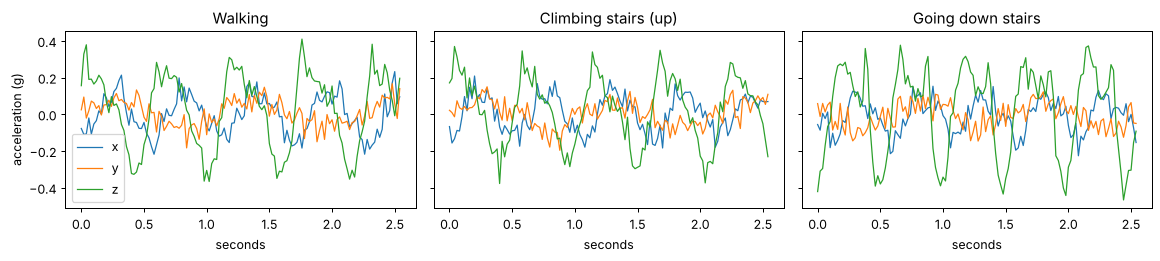

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
t = np.arange(WIN) / FS
for ax, act in zip(axes, ACTIVITIES):
    i = meta.index[meta.activity == act][0]
    for k, name in enumerate("xyz"):
        ax.plot(t, traces[i, k], label=name, lw=1)
    ax.set_title(LABELS[act]); ax.set_xlabel("seconds")
axes[0].set_ylabel("acceleration (g)"); axes[0].legend()
plt.tight_layout(); plt.show()

## 2. Turn each window into features
Instead of feeding 384 raw numbers to the network, we summarize each window with 16 easy-to-explain numbers:
how much each axis moves (standard deviation and range), the overall shake (magnitude) and its peaks,
how "spiky" the vertical signal is (kurtosis), and the **step rhythm** found with a Fourier transform
(dominant frequency) plus how much energy sits at low vs. high frequencies.

In [4]:
FEATURE_NAMES = []
def features(xyz):
    x, y, z = xyz
    mag = np.sqrt(x**2 + y**2 + z**2)
    feats = {}
    for name, sig in zip("xyz", (x, y, z)):
        feats[f"{name}_std"] = sig.std()
        feats[f"{name}_range"] = sig.max() - sig.min()
    feats["mag_mean"] = mag.mean()
    feats["mag_std"] = mag.std()
    feats["mag_max"] = mag.max()
    feats["z_kurtosis"] = kurtosis(z)
    feats["z_skew"] = skew(z)
    spec = np.abs(np.fft.rfft(z - z.mean())) ** 2
    freqs = np.fft.rfftfreq(WIN, 1 / FS)
    band = (freqs > 0.5) & (freqs < 3.5)
    feats["step_freq"] = freqs[band][np.argmax(spec[band])]
    total = spec.sum() + 1e-9
    feats["energy_low"] = spec[(freqs >= 0.5) & (freqs < 2.5)].sum() / total
    feats["energy_mid"] = spec[(freqs >= 2.5) & (freqs < 5)].sum() / total
    feats["energy_high"] = spec[freqs >= 5].sum() / total
    zc = np.sum(np.diff(np.sign(z - z.mean())) != 0)
    feats["z_zero_cross"] = zc
    return feats

feat_df = pd.DataFrame([features(w) for w in traces])
FEATURE_NAMES = list(feat_df.columns)
X = feat_df.values
y = meta["activity"].values
groups = meta["person"].values
print(len(FEATURE_NAMES), "features:", FEATURE_NAMES)

16 features: ['x_std', 'x_range', 'y_std', 'y_range', 'z_std', 'z_range', 'mag_mean', 'mag_std', 'mag_max', 'z_kurtosis', 'z_skew', 'step_freq', 'energy_low', 'energy_mid', 'energy_high', 'z_zero_cross']


## 3. Split by person: 24 people for training, 6 held-out people for testing
Splitting by **person** (not by window) matters: windows from the same person look alike, so testing on
people the model has already seen would overstate how well it works on someone new.

In [5]:
person_ids = np.array([p["person"] for p in people])
test_people = rng.choice(person_ids, size=6, replace=False)
test_mask = np.isin(groups, test_people)
X_train, y_train, g_train = X[~test_mask], y[~test_mask], groups[~test_mask]
X_test, y_test = X[test_mask], y[test_mask]
print("Test people:", sorted(test_people.tolist()))
print("Train windows:", len(y_train), "| Test windows:", len(y_test))

Test people: [4, 9, 15, 16, 18, 22]
Train windows: 2880 | Test windows: 720


## 4. Tune the network using only the training people
We try a few network sizes and regularization strengths with 4-fold cross-validation **grouped by person**.
The test set is not touched here.

In [6]:
def make_model(hidden, alpha):
    return make_pipeline(StandardScaler(),
                         MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, max_iter=2000,
                                       early_stopping=False, random_state=SEED))

results = []
gkf = GroupKFold(n_splits=4)
for hidden in [(8,), (16,), (32, 16)]:
    for alpha in [1e-4, 1e-2, 1e-1]:
        scores = []
        for tr, va in gkf.split(X_train, y_train, g_train):
            m = make_model(hidden, alpha).fit(X_train[tr], y_train[tr])
            scores.append(accuracy_score(y_train[va], m.predict(X_train[va])))
        results.append({"hidden_layers": str(hidden), "alpha": alpha, "cv_accuracy": np.mean(scores)})
tuning = pd.DataFrame(results).sort_values("cv_accuracy", ascending=False)
print(tuning.to_string(index=False))
best = tuning.iloc[0]
BEST_HIDDEN, BEST_ALPHA = eval(best["hidden_layers"]), best["alpha"]
print("Chosen:", BEST_HIDDEN, BEST_ALPHA)

hidden_layers  alpha  cv_accuracy
        (16,) 0.1000     0.875694
        (16,) 0.0001     0.872569
        (16,) 0.0100     0.872222
     (32, 16) 0.1000     0.867014
         (8,) 0.0100     0.864236
         (8,) 0.1000     0.861458
         (8,) 0.0001     0.861458
     (32, 16) 0.0001     0.855556
     (32, 16) 0.0100     0.853819
Chosen: (16,) 0.1


## 5. Train the final model and compare it to a baseline on the test set

In [7]:
model = make_model(BEST_HIDDEN, BEST_ALPHA).fit(X_train, y_train)
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

pred = model.predict(X_test)
proba = model.predict_proba(X_test)
classes = list(model.classes_)
base_pred = baseline.predict(X_test)

nn_acc = accuracy_score(y_test, pred)
base_acc = accuracy_score(y_test, base_pred)
print(f"Neural network test accuracy: {nn_acc:.1%}")
print(f"Baseline (always '{base_pred[0]}') test accuracy: {base_acc:.1%}")
print(classification_report(y_test, pred, digits=3))

cm = confusion_matrix(y_test, pred, labels=ACTIVITIES)
cm_df = pd.DataFrame(cm, index=[f"true {a}" for a in ACTIVITIES], columns=[f"pred {a}" for a in ACTIVITIES])
cm_df

Neural network test accuracy: 89.4%
Baseline (always 'downstairs') test accuracy: 33.3%
              precision    recall  f1-score   support

  downstairs      0.963     0.963     0.963       240
    upstairs      0.885     0.863     0.873       240
     walking      0.837     0.858     0.848       240

    accuracy                          0.894       720
   macro avg      0.895     0.894     0.895       720
weighted avg      0.895     0.894     0.895       720



,pred walking,pred upstairs,pred downstairs
true walking,206,27,7
true upstairs,31,207,2
true downstairs,9,0,231


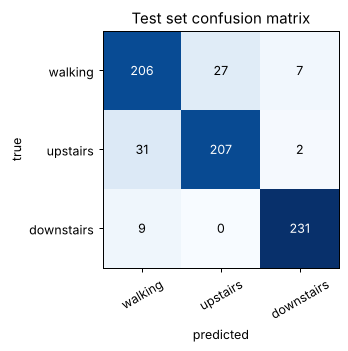

In [8]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), ACTIVITIES, rotation=30); ax.set_yticks(range(3), ACTIVITIES)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
ax.set_title("Test set confusion matrix")
plt.tight_layout(); plt.show()

## 6. Look closely at one mistake
We pick the walking-vs-stairs-up mistake the network was **most confident** about (that pair is the hardest to tell apart) and compare it to what that activity
normally looks like.

In [9]:
test_idx = np.where(test_mask)[0]
conf = proba.max(axis=1)
# focus on the hardest pair: walking vs. climbing stairs up
wrong = np.where((pred != y_test) & np.isin(y_test, ["walking", "upstairs"]) & np.isin(pred, ["walking", "upstairs"]))[0]
spot = wrong[np.argmax(conf[wrong])]
gi = test_idx[spot]
m = meta.iloc[gi]
train_steps = feat_df[~test_mask].groupby(meta.activity[~test_mask])["step_freq"].median()
print(f"Window #{gi}: person {m.person}, truly '{m.activity}', predicted '{pred[spot]}' "
      f"with {conf[spot]:.0%} confidence")
print(f"This window's measured step rhythm: {feat_df.loc[gi, 'step_freq']:.2f} steps/s "
      f"(this person's usual pace: {m.person_cadence:.2f})")
print("Typical measured step rhythm in training data:\n", train_steps.round(2))

Window #1832: person 16, truly 'walking', predicted 'upstairs' with 99% confidence
This window's measured step rhythm: 1.56 steps/s (this person's usual pace: 1.58)
Typical measured step rhythm in training data:
 activity
downstairs    1.95
upstairs      1.56
walking       1.95
Name: step_freq, dtype: float64


In [10]:
SPOTLIGHT_EXPLANATION = (
    f"This person was truly {LABELS[m.activity].lower()}, but the network said "
    f"'{LABELS[pred[spot]].lower()}' with {conf[spot]:.0%} confidence. Their step rhythm in this window was "
    f"{feat_df.step_freq.iloc[gi]:.2f} steps per second (this simulated person is a naturally slow walker), which is closer to the typical "
    f"{LABELS[pred[spot]].lower()} pace ({train_steps[pred[spot]]:.2f}) than to the typical "
    f"{LABELS[m.activity].lower()} pace ({train_steps[m.activity]:.2f}) in our training data. "
    "Accelerometer bounce alone can't tell whether you're going up in height. Things that might have helped: "
    "a barometer (air-pressure) reading that shows height change, longer windows so the model sees more steps, "
    "or more training people with unusually slow or fast paces."
)
print(SPOTLIGHT_EXPLANATION)

This person was truly walking, but the network said 'climbing stairs (up)' with 99% confidence. Their step rhythm in this window was 1.56 steps per second (this simulated person is a naturally slow walker), which is closer to the typical climbing stairs (up) pace (1.56) than to the typical walking pace (1.95) in our training data. Accelerometer bounce alone can't tell whether you're going up in height. Things that might have helped: a barometer (air-pressure) reading that shows height change, longer windows so the model sees more steps, or more training people with unusually slow or fast paces.


## 7. Export held-out predictions for the website
The site shows a gallery of test-set windows (people the model never saw). We include a mix of correct
predictions and mistakes, plus the summary numbers the site guide and chatbot rely on.

In [11]:
gallery_ids = []
rng_g = np.random.default_rng(7)
for act in ACTIVITIES:
    right_ones = [i for i in range(len(y_test)) if y_test[i] == act and pred[i] == act]
    wrong_ones = [i for i in range(len(y_test)) if y_test[i] == act and pred[i] != act and i != spot]
    gallery_ids += list(rng_g.choice(right_ones, 4, replace=False))
    gallery_ids += list(rng_g.choice(wrong_ones, min(1, len(wrong_ones)), replace=False))
rest = [int(i) for i in gallery_ids]
rng_g.shuffle(rest)
gallery_ids = [int(spot)] + rest   # the spotlight mistake is listed first; the site shuffles the game order

def pack(i):
    g = test_idx[i]
    return {
        "id": int(g),
        "person": int(meta.person.iloc[g]),
        "true": y_test[i],
        "pred": pred[i],
        "probs": {c: round(float(p), 3) for c, p in zip(classes, proba[i])},
        "steps_per_sec": round(float(feat_df.step_freq.iloc[g]), 2),
        "x": np.round(traces[g, 0], 3).tolist(),
        "y": np.round(traces[g, 1], 3).tolist(),
        "z": np.round(traces[g, 2], 3).tolist(),
    }

per_class_recall = {a: round(float(cm[k, k] / cm[k].sum()), 3) for k, a in enumerate(ACTIVITIES)}
exhibit = {
    "activities": ACTIVITIES,
    "labels": LABELS,
    "sample_rate_hz": FS,
    "window_seconds": WIN / FS,
    "summary": {
        "n_people": N_PEOPLE, "n_train_windows": int(len(y_train)), "n_test_windows": int(len(y_test)),
        "n_test_people": 6, "nn_accuracy": round(float(nn_acc), 3), "baseline_accuracy": round(float(base_acc), 3),
        "baseline_rule": f"always guess '{base_pred[0]}'",
        "per_class_recall": per_class_recall,
        "confusion_matrix": cm.tolist(),
        "hidden_layers": list(BEST_HIDDEN), "alpha": float(BEST_ALPHA),
        "n_features": len(FEATURE_NAMES), "features": FEATURE_NAMES,
    },
    "spotlight": {"id": int(test_idx[spot]), "explanation": SPOTLIGHT_EXPLANATION},
    "gallery": [pack(i) for i in gallery_ids],
}
OUT_DIR = "../data" if os.path.isdir("../data") else "."
with open(os.path.join(OUT_DIR, "exhibit.json"), "w") as fh:
    json.dump(exhibit, fh)
print("Wrote", os.path.join(OUT_DIR, "exhibit.json"), "with", len(exhibit["gallery"]), "gallery windows")
print(json.dumps(exhibit["summary"], indent=1)[:800])

Wrote ../data/exhibit.json with 16 gallery windows
{
 "n_people": 30,
 "n_train_windows": 2880,
 "n_test_windows": 720,
 "n_test_people": 6,
 "nn_accuracy": 0.894,
 "baseline_accuracy": 0.333,
 "baseline_rule": "always guess 'downstairs'",
 "per_class_recall": {
  "walking": 0.858,
  "upstairs": 0.863,
  "downstairs": 0.963
 },
 "confusion_matrix": [
  [
   206,
   27,
   7
  ],
  [
   31,
   207,
   2
  ],
  [
   9,
   0,
   231
  ]
 ],
 "hidden_layers": [
  16
 ],
 "alpha": 0.1,
 "n_features": 16,
 "features": [
  "x_std",
  "x_range",
  "y_std",
  "y_range",
  "z_std",
  "z_range",
  "mag_mean",
  "mag_std",
  "mag_max",
  "z_kurtosis",
  "z_skew",
  "step_freq",
  "energy_low",
  "energy_mid",
  "energy_high",
  "z_zero_cross"
 ]
}
